In [1]:
!git clone https://github.com/ptmacd2/COSC-311_Project.git

Cloning into 'COSC-311_Project'...
remote: Enumerating objects: 16, done.
remote: Counting objects: 100% (16/16), done.
remote: Compressing objects: 100% (14/14), done.
remote: Total 16 (delta 0), reused 16 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (16/16), 6.55 KiB | 1.64 MiB/s, done.


In [1]:
class ListeningEvent:
    def __init__(self, listener_id, listener_name, title, artist, timestamp, seconds_played):
        self.listener_id = listener_id
        self.listener_name = listener_name
        self.title = title
        self.artist = artist
        self.timestamp = timestamp
        self.seconds_played = seconds_played


def parse_line(line):
    line = line.strip()
    if not line:
        raise ValueError("blank line")
    parts = line.split(" | ")
    if len(parts) != 6:
        raise ValueError(f"expected 6 fields, got {len(parts)}")
    listener_id, listener_name, title, artist, timestamp, seconds = parts
    return ListeningEvent(listener_id, listener_name, title, artist, timestamp, int(seconds))

In [2]:
events = []
skipped = 0
total_lines = 0

with open("streambeats_log.txt", "r") as f:
    for line in f:
        total_lines += 1
        try:
            events.append(parse_line(line))
        except (ValueError, IndexError):
            skipped += 1

print(len(events), "recovered,", skipped, "skipped")

343 recovered, 57 skipped


In [3]:
with open("recovery_report.txt", "w") as f:
    print("StreamBeats Recovery Report", file=f)
    print(f"Total lines in log: {total_lines}", file=f)
    print(f"Successfully recovered: {len(events)}", file=f)
    print(f"Skipped: {skipped}", file=f)

In [15]:
import numpy as np
import pandas as pd
listeningEvents = []
for event in events:
    listeningEvents.append({
        "listener_id": event.listener_id,
        "listener_name": event.listener_name,
        "song_title": event.title,
        "artist": event.artist,
        "timestamp": event.timestamp,
        "seconds_played": event.seconds_played
    })
events_df = pd.DataFrame(listeningEvents)
print(events_df.head())

  listener_id listener_name       song_title       artist         timestamp  \
0        L102     Marcus T.      Gravel Road  Tomas Reyes  2026-03-21 18:00   
1        L103        Wei L.      Gravel Road  Tomas Reyes  2026-03-24 00:00   
2        L102     Marcus T.        Neon Tide   Kalea Voss  2026-03-05 08:00   
3        L104        Ava R.   Midnight Ferry     Yuna Cho  2026-03-02 21:00   
4        L103        Wei L.  Dust and Static     Nightjar  2026-03-25 20:00   

   seconds_played  
0             179  
1             173  
2              38  
3             105  
4             116  


In [7]:
song_genres = {
    "Neon Tide": "Synthpop",
    "Gravel Road": "Country",
    "Static Bloom": "Indie Rock",
    "Midnight Ferry": "R&B",
    "Paper Lanterns": "Folk",
    "Circuit Heart": "Synthpop",
    "Dust and Static": "Indie Rock"
}
events_df["genre"] = events_df["song_title"].map(song_genres)

genre_totals = (
    events_df.groupby("genre")["seconds_played"]
    .sum()
    .sort_values(ascending=False)
)

print(genre_totals)

genre
Indie Rock    12231
Synthpop      10271
R&B            6661
Folk           6011
Country        5534
Name: seconds_played, dtype: int64


In [8]:
artist_counts = events_df["artist"].value_counts()
most_played_artist = artist_counts.idxmax()
print("Most-played artist:", most_played_artist)
artist_events = events_df[
    events_df["artist"] == most_played_artist
]
print(artist_events)

Most-played artist: Nightjar
    listener_id listener_name       song_title    artist         timestamp  \
4          L103        Wei L.  Dust and Static  Nightjar  2026-03-25 20:00   
6          L105      Diego F.     Static Bloom  Nightjar  2026-03-24 20:00   
8          L104        Ava R.     Static Bloom  Nightjar  2026-03-12 21:00   
14         L103        Wei L.     Static Bloom  Nightjar  2026-03-14 02:00   
15         L104        Ava R.  Dust and Static  Nightjar  2026-03-22 14:00   
..          ...           ...              ...       ...               ...   
325        L102     Marcus T.     Static Bloom  Nightjar  2026-03-07 11:00   
327        L102     Marcus T.     Static Bloom  Nightjar  2026-03-24 01:00   
330        L102     Marcus T.     Static Bloom  Nightjar  2026-03-02 21:00   
337        L105      Diego F.     Static Bloom  Nightjar  2026-03-12 13:00   
339        L104        Ava R.  Dust and Static  Nightjar  2026-03-20 05:00   

     seconds_played       genre  


In [9]:
song_averages = events_df.groupby("song_title")["seconds_played"].mean()
averages = np.array(song_averages.values)
popularity_percentages = (averages / np.max(averages)) * 100
popularity_df = pd.DataFrame({
    "song_title": song_averages.index,
    "average_seconds_played": averages,
    "popularity_percentage": popularity_percentages
})

print(popularity_df.sort_values(
    "popularity_percentage", ascending=False
))

        song_title  average_seconds_played  popularity_percentage
6     Static Bloom              134.888889             100.000000
4        Neon Tide              133.282051              98.808769
1  Dust and Static              126.846154              94.037511
2      Gravel Road              120.304348              89.187737
3   Midnight Ferry              114.844828              85.140317
0    Circuit Heart              107.936170              80.018578
5   Paper Lanterns              100.183333              74.271005


<Axes: title={'center': 'Total Listening Time by Genre'}, xlabel='Genre', ylabel='Total Seconds Played'>

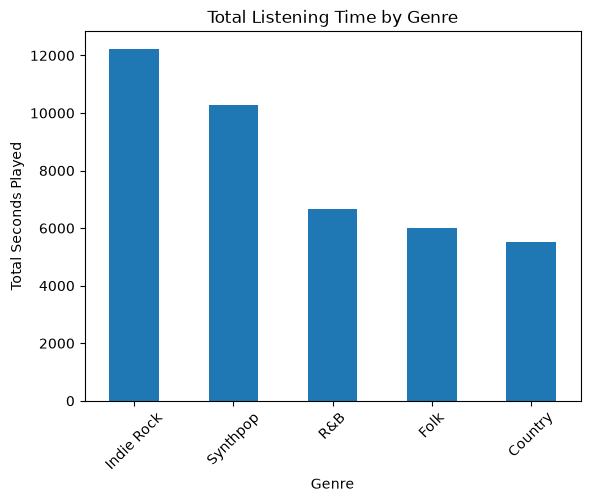

In [12]:
genre_totals.plot.bar(
    title="Total Listening Time by Genre",
    xlabel="Genre",
    ylabel="Total Seconds Played",
    rot = 45
)

<Axes: title={'center': 'Listening Activity by Hour of Day'}, xlabel='Hour of Day (0–23)', ylabel='Number of Listening Events'>

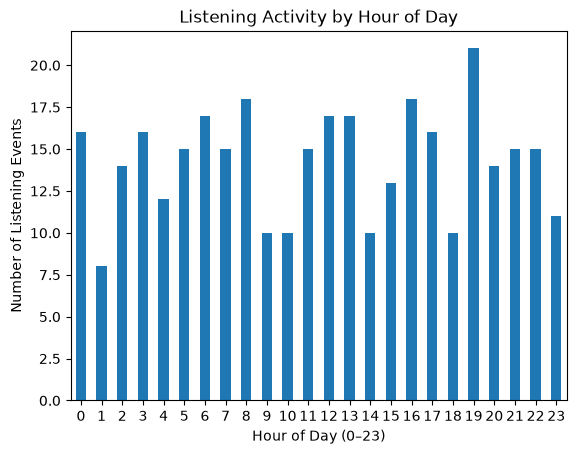

In [13]:
events_df["hour"] = pd.to_datetime(events_df["timestamp"]).dt.hour
hourly_listens = events_df.groupby("hour").size()

hourly_listens.plot.bar(
    title="Listening Activity by Hour of Day",
    xlabel="Hour of Day (0–23)",
    ylabel="Number of Listening Events",
    rot=0
)

In [14]:
events_df["day"] = pd.to_datetime(events_df["timestamp"]).dt.day
daily_genre_totals = (
    events_df.groupby(["day", "genre"], as_index=False)
    ["seconds_played"].sum()
)

genre_pivot = daily_genre_totals.pivot(
    index="day",
    columns="genre",
    values="seconds_played"
)

print(genre_pivot)

genre  Country   Folk  Indie Rock    R&B  Synthpop
day                                               
1         85.0  292.0       387.0  628.0     985.0
2        406.0  293.0       707.0  170.0     533.0
3        518.0   61.0       420.0  370.0     267.0
4        193.0  300.0       482.0  184.0     900.0
5          NaN  185.0       645.0  355.0     403.0
6        145.0  316.0      1240.0  231.0     308.0
7        241.0    NaN       458.0  272.0     140.0
8        126.0  266.0       256.0  239.0     257.0
9          NaN  145.0       409.0  149.0      20.0
10       152.0    NaN        66.0   73.0     420.0
11       182.0  164.0       530.0  337.0     621.0
12       189.0  303.0       446.0  559.0     606.0
13         NaN  412.0       316.0   45.0     339.0
14         NaN  310.0       236.0  378.0      79.0
15       436.0  246.0       260.0  194.0     184.0
16         NaN    NaN       499.0  363.0     198.0
17        20.0   30.0       107.0    NaN     371.0
18       556.0  154.0       568

#Part 4: The Case File

The findings from part 3 are as follows:
1. Indie Rock was the genre that was most listened to with 12,231 seconds and Country was the least listened with 5534 seconds.
2. Nightjar was the most played artist where he appeared in 93 out of the 343 recovered listening events.
3. The pivot table shows daily variation in listening preferences where Indie Rock reached its highest daily total on March 6 at 1,240 seconds.